# Static on the v7 grid, with the space charge fixed (2026-10-22)
**Space charge** (from CM_laser_SC_QA_v7.ipynb): South α 1.7 kink 25 b 0.60, North α 1.6 kink 25 b 0.55,
keff = b × I_median (per-side median GEM current), no offset.

**Grid** (v7 S): IFC, OFC, frame charge each −40 / 0 / +40 around the v4 joint solution (South IFC −36 / OFC −17 V /
frames −110, North −138 / −41 V / −165, voltages vs automatic), m = 120 module-frame maps, 27 points, run static-only on
the 11 blocks of 795xx and on no beam 75073 / 83319 (and field off 78242).

**Space charge added by superposition**: P(grid point, SC) = P(static only at the point) + [P(SC map) − P(static only)] at
the grid centre, measured on the same blocks. Checked against the α 1.8 configurations that ran explicitly at every
grid point (Section 1).

**Profiles**: dφ [mrad] and RΔφ [mm] vs R (2 cm), K0s-weighted φ average vs the fully aligned truth, sector edges excluded,
**all bins** (the R² metric is the K0s-calibrated one: K0s balance = +4 + 1.11 × R²; with the 30–32 cm bin dropped R²
would read +230 µm (S) / +100 µm (N) higher – that bin is unreliable only at high current).
Every quantity is fitted linearly in the three knobs over the 27 points.

**Joint fit**: Σ_R [(dφ − ⟨dφ⟩)/0.1 mrad]²/n_R + (R²/50 µm)² + (pointing/0.3 mm)² + (steps/0.1 mm)² [+ (R1 arch/0.1 mrad)²]
+ 0.1 |knob step / 40|² (pull to the grid centre); the rotation ⟨dφ⟩ free.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
import cmplots as c, truthalign as ta, static7 as st, scqa as q
plt.rcParams['figure.dpi'] = 72
plt.rcParams.update({'font.size': 13, 'axes.titlesize': 13, 'axes.labelsize': 13, 'legend.fontsize': 9.5})
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')
ta.correct_truth()
def qline(Q):
    return f"dphi rms {Q['rms']:.2f} mrad, shift {Q['shift']:+.2f} mm, R2 {Q['R2']:+5.0f} um, pointing {Q['pointing']:+.2f} mm, steps {Q['step1']:+.2f} / {Q['step2']:+.2f} mm, R1 arch {Q['arch']:+.2f} mrad"

## 1. Checks: superposition and linearity

In [2]:
for s in (0, 1):
    A = st.additivity(s)
    print(f"{c.SIDES[s]}: explicit alpha 1.8 vs superposition, dphi rms difference per grid point: median {np.median(A):.3f}, max {A.max():.3f} mrad")
    for nm, runs in (('795xx + SC', st.BEAM), ('75073', ('75073',)), ('83319', ('83319',))):
        print(f"      linear model ({nm}): rms of the 27 profiles about the model {st.linear_model(s, runs)['fit_rms']:.3f} mrad")

Welcome to JupyROOT 6.30/06


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/static7.py:53: RuntimeWarning: Mean of empty slice
  P = np.nanmean(P, axis=0) if P else np.full(len(R), np.nan)


South: explicit alpha 1.8 vs superposition, dphi rms difference per grid point: median 0.118, max 0.163 mrad


      linear model (795xx + SC): rms of the 27 profiles about the model 0.055 mrad


      linear model (75073): rms of the 27 profiles about the model 0.022 mrad


      linear model (83319): rms of the 27 profiles about the model 0.022 mrad


North: explicit alpha 1.8 vs superposition, dphi rms difference per grid point: median 0.037, max 0.065 mrad


      linear model (795xx + SC): rms of the 27 profiles about the model 0.018 mrad


      linear model (75073): rms of the 27 profiles about the model 0.023 mrad


      linear model (83319): rms of the 27 profiles about the model 0.018 mrad


Superposition holds to ≈ 0.12 mrad (South) / 0.04 mrad (North) – well below the effects fitted; the knobs act linearly
(model rms ≤ 0.06 mrad).

## 2. What each knob does (795xx with the space charge, and no beam)
Per +40 V / +40 frame charge. Labels: R², pointing, sideways shift, R1 arch of each response.

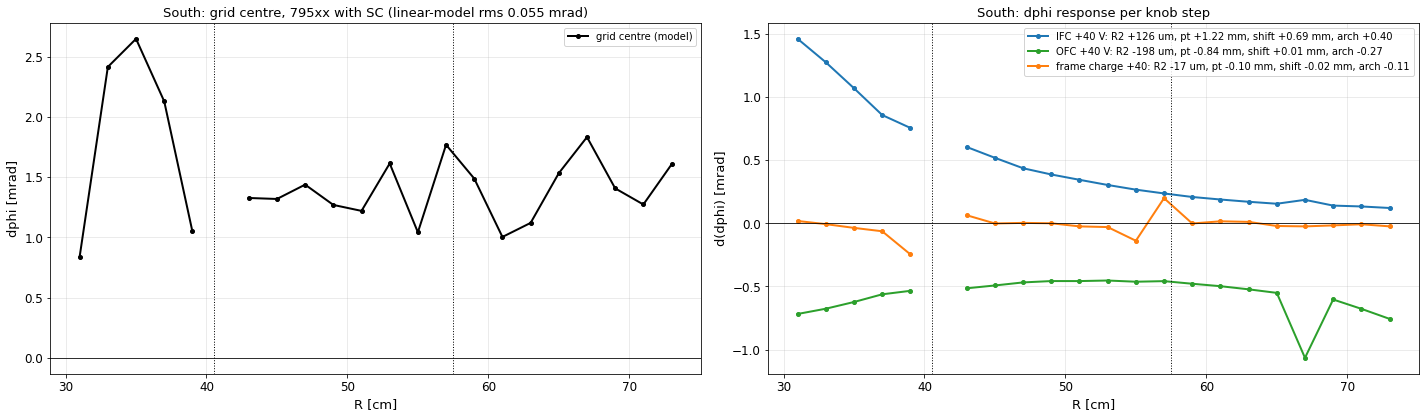

In [3]:
show(st.fig_responses(0))

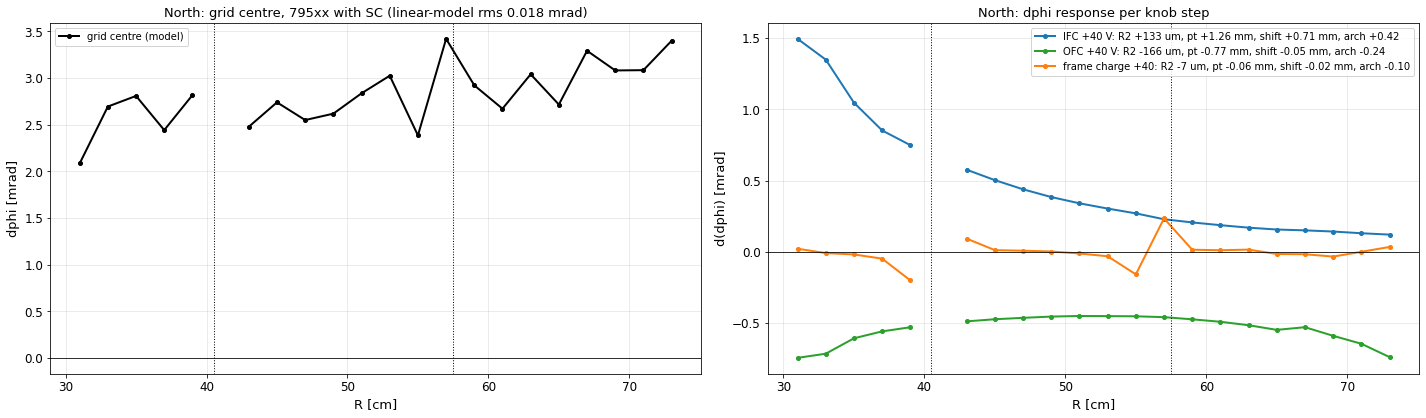

In [4]:
show(st.fig_responses(1))

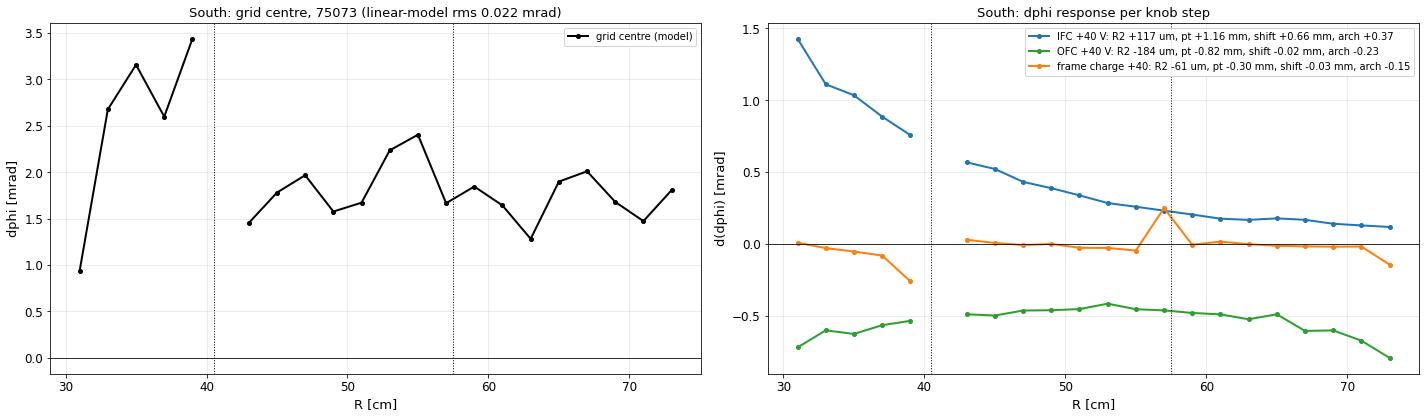

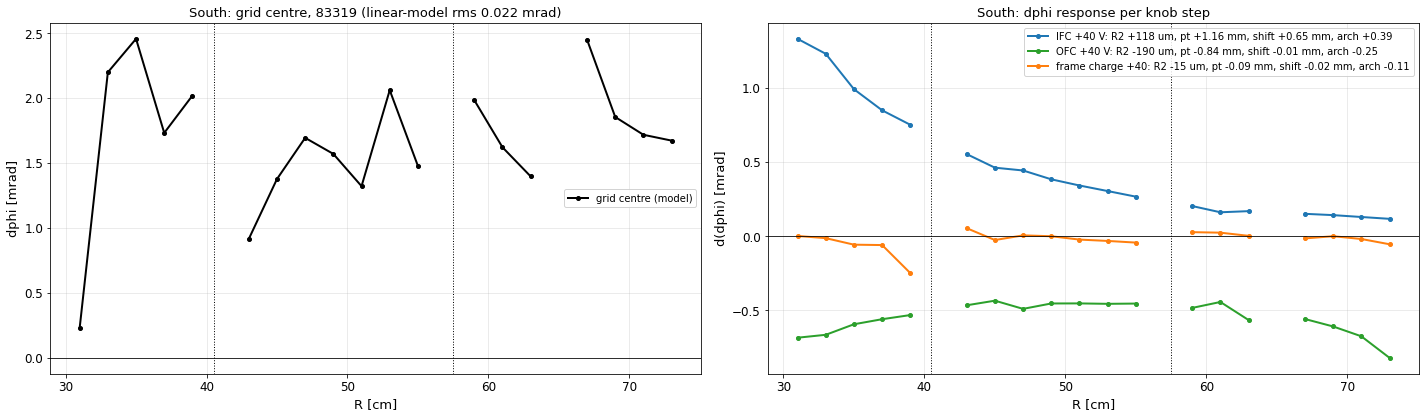

In [5]:
show(st.fig_responses(0, ('75073',)), st.fig_responses(0, ('83319',)))

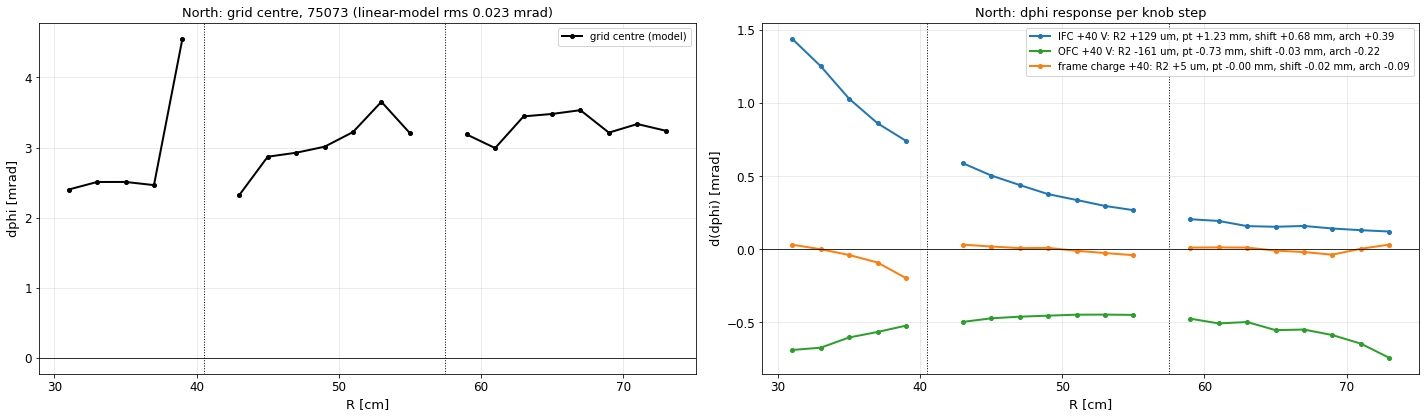

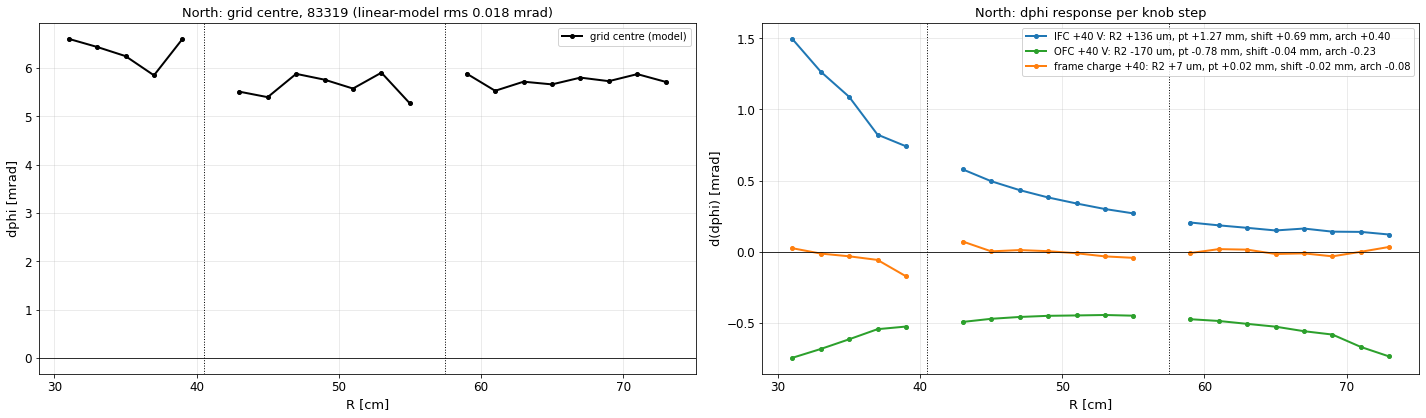

In [6]:
show(st.fig_responses(1, ('75073',)), st.fig_responses(1, ('83319',)))

- **IFC** (+40 V): R² +126 / +133 µm, pointing +1.2 mm, sideways shift +0.7 mm, **R1 arch +0.4 mrad** – the inner field
  cage acts on R1 most.
- **OFC** (+40 V): R² −198 / −166 µm, pointing −0.8 mm, no shift, arch −0.25 mrad.
- **Frames** (+40): module steps (+0.15 mm at 40.5 cm, −0.1 at 57.5 cm), little else.
- The R1 arch is tied to R² and pointing through the same two field-cage knobs: it cannot be removed alone.

## 3. The solutions

In [7]:
for s in (0, 1):
    for nm, o, Q in st.table(s):
        k = ' ' * 47 if o is None else f"IFC {o['IFC']:+5.0f} V, OFC {o['OFC']:+5.0f} V, frames {o['frame']:+5.0f}"
        print(f"{c.SIDES[s]:5s} {nm:30s} {k} | {qline(Q)}")
    print()

South CDB, 795xx                                                                     | dphi rms 0.58 mrad, shift +0.50 mm, R2   -31 um, pointing +0.41 mm, steps -0.17 / +0.28 mm, R1 arch +0.73 mrad
South 795xx + SC: joint              IFC   -51 V, OFC   +17 V, frames  -152 | dphi rms 0.40 mrad, shift +0.00 mm, R2    -2 um, pointing +0.03 mm, steps +0.05 / +0.07 mm, R1 arch +0.53 mrad
South 795xx + SC: joint + R1 arch    IFC   -62 V, OFC   +19 V, frames  -124 | dphi rms 0.43 mrad, shift -0.20 mm, R2   -58 um, pointing -0.42 mm, steps +0.15 / +0.01 mm, R1 arch +0.33 mrad
South 795xx + SC: dphi only          IFC   -50 V, OFC   +13 V, frames  -147 | dphi rms 0.40 mrad, shift +0.02 mm, R2   +18 um, pointing +0.13 mm, steps +0.07 / +0.06 mm, R1 arch +0.55 mrad
South no beam 75073: joint           IFC   -55 V, OFC   -82 V, frames   +45 | dphi rms 0.44 mrad, shift +0.02 mm, R2    -3 um, pointing +0.03 mm, steps -0.30 / -0.32 mm, R1 arch +0.75 mrad
South no beam 75073: joint + R1 arch IFC   -74

North CDB, 795xx                                                                     | dphi rms 0.83 mrad, shift +1.45 mm, R2   +50 um, pointing +1.71 mm, steps -0.31 / -0.13 mm, R1 arch +0.78 mrad
North 795xx + SC: joint              IFC  -112 V, OFC   +17 V, frames  -183 | dphi rms 0.23 mrad, shift -0.00 mm, R2    +2 um, pointing +0.01 mm, steps -0.15 / -0.21 mm, R1 arch +0.25 mrad
North 795xx + SC: joint + R1 arch    IFC  -117 V, OFC   +18 V, frames  -170 | dphi rms 0.25 mrad, shift -0.11 mm, R2   -23 um, pointing -0.21 mm, steps -0.10 / -0.24 mm, R1 arch +0.16 mrad
North 795xx + SC: dphi only          IFC  -114 V, OFC    +4 V, frames  -198 | dphi rms 0.23 mrad, shift -0.01 mm, R2   +54 um, pointing +0.23 mm, steps -0.21 / -0.17 mm, R1 arch +0.35 mrad
North no beam 75073: joint           IFC  -100 V, OFC   -22 V, frames  +173 | dphi rms 0.31 mrad, shift -0.01 mm, R2    -3 um, pointing -0.02 mm, steps -0.17 / +0.16 mm, R1 arch -0.22 mrad
North no beam 75073: joint + R1 arch IFC   -97

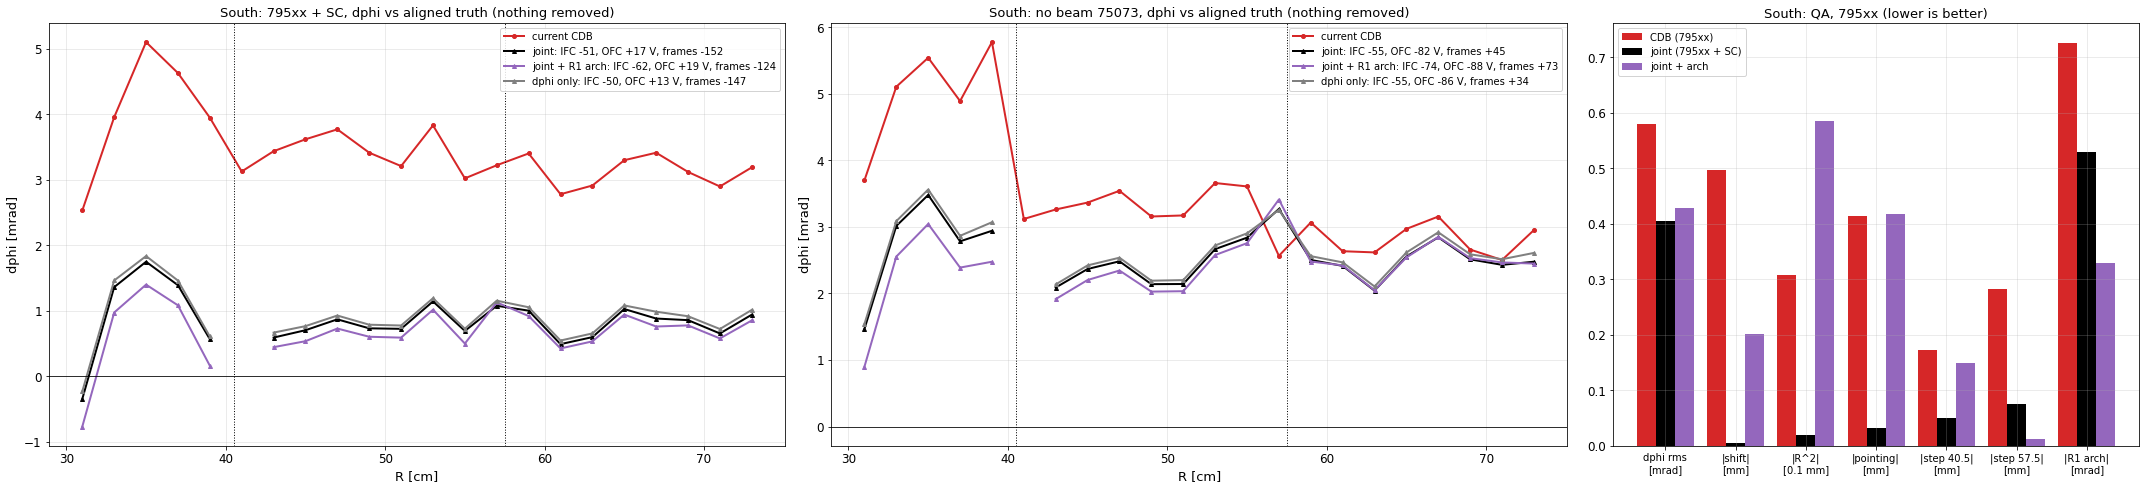

In [8]:
show(st.fig_solution(0))

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/static7.py:53: RuntimeWarning: Mean of empty slice
  P = np.nanmean(P, axis=0) if P else np.full(len(R), np.nan)


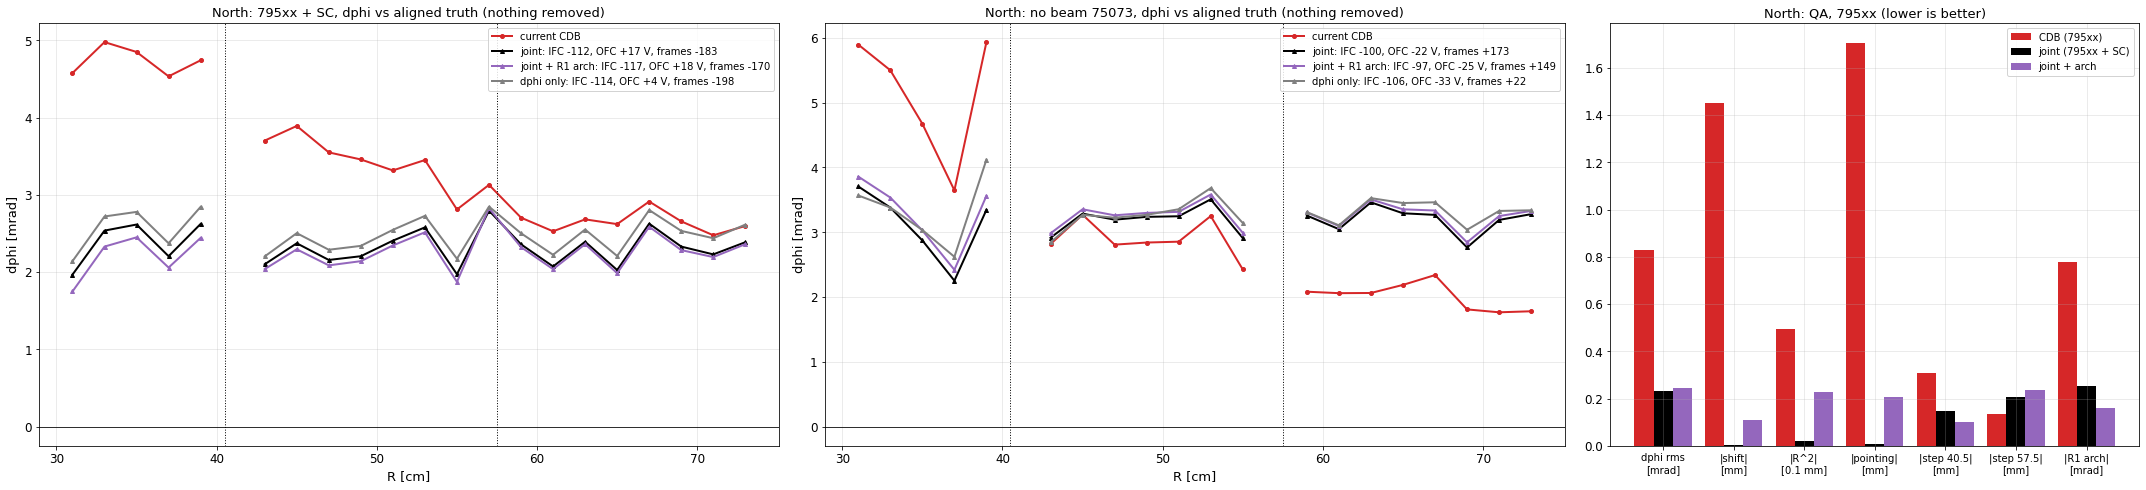

In [9]:
show(st.fig_solution(1))

**795xx with the space charge (the calibration)** – voltages vs automatic:

| | IFC | OFC | frames | dφ rms (CDB) | shift (CDB) | R² (CDB) | pointing (CDB) | steps (CDB) | R1 arch (CDB) |
|---|---|---|---|---|---|---|---|---|---|
| South | −51 V | +17 V | −152 | 0.40 (0.58) | 0.00 (0.50) mm | −2 (−31) µm | 0.03 (0.41) mm | +0.05 / +0.07 (−0.17 / +0.28) | +0.53 (+0.73) |
| North | −112 V | +17 V | −183 | 0.23 (0.83) | 0.00 (1.45) mm | +2 (+50) µm | 0.01 (1.71) mm | −0.15 / −0.21 (−0.31 / −0.13) | +0.25 (+0.78) |

- Better than the CDB in every number except the North 57.5 cm step.
- vs the v4 joint fit (α 1.8, CDB frame maps): the OFC moves up (South −17 → +17, North −41 → +17 V), the North IFC
  comes down (−138 → −112 V), frames more negative (−107 → −152 S): the α 1.6–1.7 space charge has less curvature, and
  the m = 120 frames act differently.
- **North OFC is +58 V from the grid centre (outside ±40)**: linear extrapolation (the model is linear to 0.02 mrad).
- **South R1 arch +0.5 mrad remains.** Weighting it in the fit (+ R1 arch) brings it to +0.33 but costs R² −58 µm and
  pointing −0.4 mm: the field-cage knobs move all three together. A separate R1 knob is needed (R1 frame charge
  separate from R2 / R3, or the inner field cage position / the inner-R1 field-off profile in the alignment).

## 4. Beam vs no beam: is the static the same?
Each solution (fitted on one data set) applied to the others through their linear models.

In [10]:
for s in (0, 1):
    for f, a, Q in st.cross_check(s):
        print(f"{c.SIDES[s]:5s} fitted on {f:10s} -> applied to {a:10s}: {qline(Q)}")
    print()

South fitted on 795xx + SC -> applied to 795xx + SC: dphi rms 0.40 mrad, shift +0.00 mm, R2    -2 um, pointing +0.03 mm, steps +0.05 / +0.07 mm, R1 arch +0.53 mrad
South fitted on 795xx + SC -> applied to 75073     : dphi rms 0.63 mrad, shift +0.16 mm, R2  -146 um, pointing -0.41 mm, steps -1.05 / +0.36 mm, R1 arch +0.97 mrad
South fitted on 795xx + SC -> applied to 83319     : dphi rms 0.58 mrad, shift -0.42 mm, R2  -123 um, pointing -0.93 mm, steps -0.66 / +0.23 mm, R1 arch +0.62 mrad
South fitted on 75073      -> applied to 795xx + SC: dphi rms 0.65 mrad, shift -0.19 mm, R2  +390 um, pointing +1.48 mm, steps +0.84 / -0.37 mm, R1 arch +0.62 mrad
South fitted on 75073      -> applied to 75073     : dphi rms 0.44 mrad, shift +0.02 mm, R2    -3 um, pointing +0.03 mm, steps -0.30 / -0.32 mm, R1 arch +0.75 mrad
South fitted on 75073      -> applied to 83319     : dphi rms 0.57 mrad, shift -0.57 mm, R2  +262 um, pointing +0.57 mm, steps -0.04 / +0.47 mm, R1 arch +0.68 mrad
South fitted on 

North fitted on 795xx + SC -> applied to 795xx + SC: dphi rms 0.23 mrad, shift -0.00 mm, R2    +2 um, pointing +0.01 mm, steps -0.15 / -0.21 mm, R1 arch +0.25 mrad
North fitted on 795xx + SC -> applied to 75073     : dphi rms 0.48 mrad, shift -0.05 mm, R2  -240 um, pointing -1.09 mm, steps -1.23 / -0.23 mm, R1 arch +0.25 mrad
North fitted on 795xx + SC -> applied to 83319     : dphi rms 0.52 mrad, shift +0.82 mm, R2  +108 um, pointing +1.26 mm, steps -0.67 / +0.38 mm, R1 arch +0.71 mrad
North fitted on 75073      -> applied to 795xx + SC: dphi rms 0.79 mrad, shift +0.06 mm, R2  +141 um, pointing +0.63 mm, steps +1.23 / -1.07 mm, R1 arch -0.26 mrad
North fitted on 75073      -> applied to 75073     : dphi rms 0.31 mrad, shift -0.01 mm, R2    -3 um, pointing -0.02 mm, steps -0.17 / +0.16 mm, R1 arch -0.22 mrad
North fitted on 75073      -> applied to 83319     : dphi rms 0.66 mrad, shift +0.92 mm, R2  +379 um, pointing +2.53 mm, steps +0.45 / +0.63 mm, R1 arch +0.32 mrad
North fitted on 

**No.** No beam wants very different knobs, and the two no-beam runs disagree with each other:
- frame charge: beam −152 (S) / −183 (N); no beam 75073 +45 / +173, 83319 −7 / −11;
- North IFC: beam −112, 75073 −100, 83319 −153 V; South OFC: beam +17, 75073 −82, 83319 −3 V.

The beam solution leaves R² −120 … −240 µm on no beam; the no-beam solutions leave +130 … +390 µm on beam.

**Interpretation.** The frame charge differs most: **the module frames charge up with beam** (ions landing on the
frames), so the frame "static" is not static – it belongs with the space charge, and should scale with the ion flux.
On top, the no-beam static moves in time (75073 vs 83319), as already seen for the North sideways shift. Consequence:
**calibrate the static on beam data** (here 795xx), not on no beam; and check the frame charge vs current on 8xxxx.

## 5. The beam solution in four φ bins

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/static7.py:199: RuntimeWarning: Mean of empty slice
  P.append(np.nanmean(pp, axis=0))


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/static7.py:210: RuntimeWarning: Mean of empty slice
  sol = B[0] + beta @ B[1:] + np.nanmean(scd, axis=0)
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/static7.py:211: RuntimeWarning: Mean of empty slice
  cdb = np.nanmean([v.wprof_q(aq.full_aligned(r, ta.v4_tag(b, 'cdb'), s)[v._phi_ok(aq.full_aligned(r, ta.v4_tag(b, 'cdb'), s)[:, 2], lo, hi)], 5) for r, b in aq.blocks(BEAM)], axis=0)


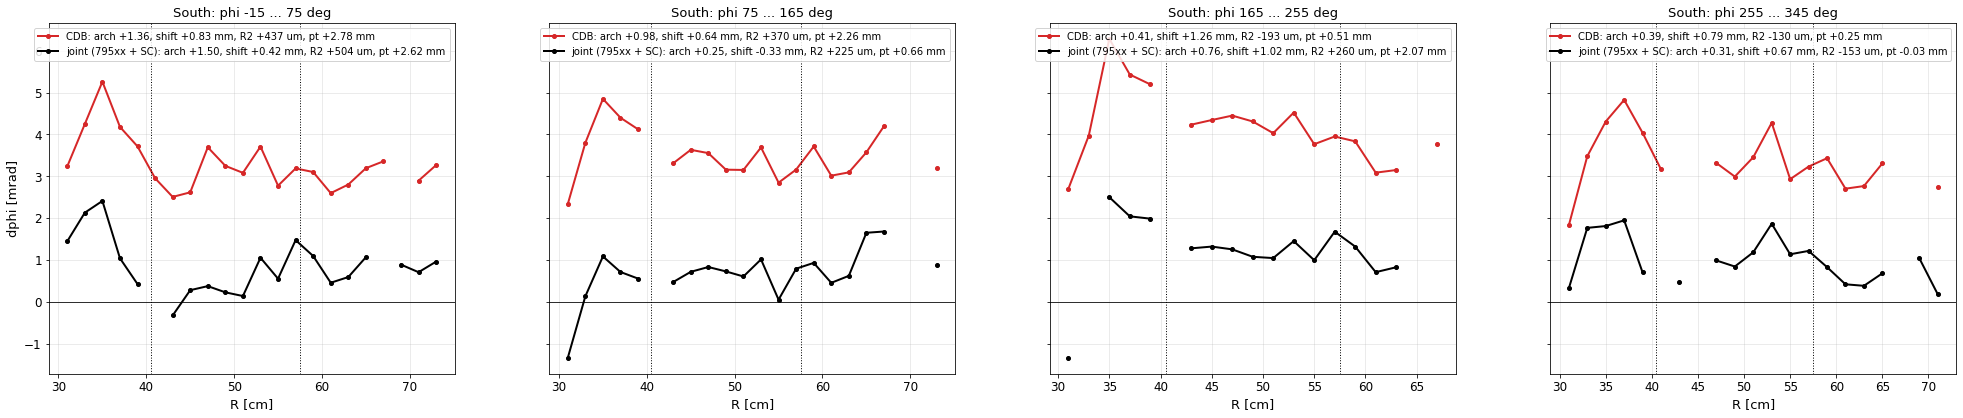

In [11]:
show(st.fig_phi_bins(0))

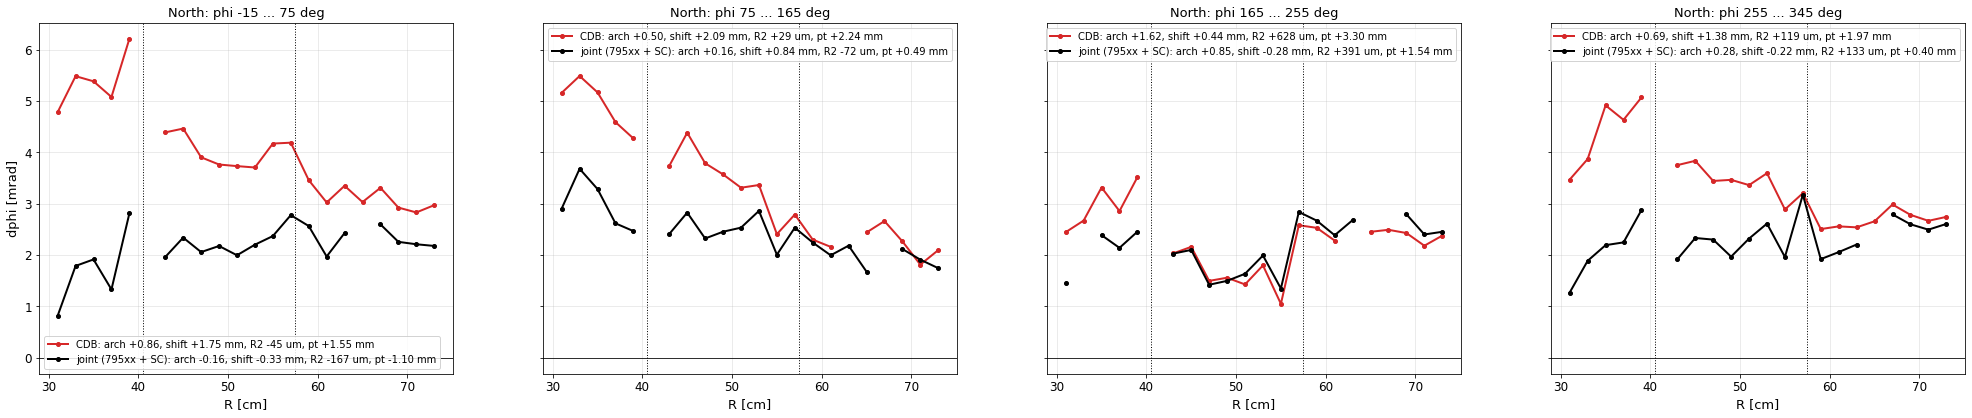

In [12]:
show(st.fig_phi_bins(1))

## 6. Summary and next
1. **Static (795xx, with the fixed space charge)**: South IFC −51 / OFC +17 V / frames −152, North IFC −112 / OFC +17 V /
   frames −183 (m = 120 frame maps). R² ≈ 0 (K0s balance ≈ 0 expected), sideways shift and pointing ≈ 0, dφ rms 0.40 /
   0.23 mrad (CDB 0.58 / 0.83).
2. **Left**: South R1 arch +0.5 mrad (needs an R1-only knob); North module steps −0.15 / −0.21 mm.
3. **No beam is not the beam static**: the frame charge goes with the beam (frame charging by ions) and the no-beam
   static moves in time.
4. **Next jobs**: (a) confirmation at the solution on all 17 beam blocks (795xx and 8xxxx) with the fixed space charge,
   with frame charge −120 / −150 / −180 / −220 at 8xxxx (does the frame charge scale with the current?);
   (b) an R1-only frame charge or IFC-position scan for the South arch; (c) then one K0s run with this calibration.